# ===== CELL 1: Mount Drive, install, init GEE =====

In [1]:
import os
from google.colab import drive

# Menyambungkan Google Drive ke Colab supaya hasil (CSV, PNG, model, TIF)
# bisa disimpan permanen dan tidak hilang saat runtime di-reset
drive.mount('/content/gdrive')

# Folder utama untuk semua output. Cukup ubah di sini kalau mau pindah lokasi
ROOT_PATH = '/content/gdrive/MyDrive/Praktek_diniyrti/Praktek_Regresi_RF'

# Buat folder kalau belum ada (exist_ok=True = tidak error kalau sudah ada)
os.makedirs(ROOT_PATH, exist_ok=True)

# Install library tambahan:
# - xee       : membaca data Earth Engine sebagai Xarray
# - geemap    : peta interaktif untuk GEE di Colab
# - rioxarray : menyimpan Xarray jadi GeoTIFF
!pip install -q --upgrade xee geemap rioxarray

import ee, geemap

# Login ke akun Google yang punya akses Earth Engine (akan muncul link/popup)
ee.Authenticate()

# Menghubungkan notebook ke GEE memakai Google Cloud Project milikmu.
# Ganti dengan Project ID (bukan Name). Endpoint high-volume dipakai
# supaya request data besar lebih lancar.
ee.Initialize(project='petakepintaran',
              opt_url='https://earthengine-highvolume.googleapis.com')


Mounted at /content/gdrive


# ===== CELL 2: AOI =====

In [2]:
# Nama provinsi harus persis seperti di dataset GAUL.
# Sulawesi Tenggara tidak boleh dipakai (sudah dipakai di kelas).
PROVINSI = 'Sulawesi Selatan'

# FAO GAUL level1 = batas administrasi tingkat provinsi seluruh dunia.
# Disaring dulu ke Indonesia, lalu ke provinsi yang dipilih,
# lalu .geometry() mengubahnya jadi satu objek geometri untuk dipakai di clip/filter
aoi = (ee.FeatureCollection('FAO/GAUL/2015/level1')
       .filter(ee.Filter.eq('ADM0_NAME', 'Indonesia'))
       .filter(ee.Filter.eq('ADM1_NAME', PROVINSI))
       .geometry())

# Membuat peta interaktif berlatar citra satelit
Map = geemap.Map(basemap='SATELLITE')
Map.addLayer(aoi, {}, PROVINSI)   # tampilkan batas AOI
Map.centerObject(aoi, 7)          # zoom ke AOI (7 = level zoom provinsi)
Map                               # tampilkan peta

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


Map(center=[-3.7190754116758713, 120.17877389060266], controls=(WidgetControl(options=['position', 'transparen…

# ===== CELL 3: Forest mask (MODIS) =====

In [3]:
# MODIS MCD12Q1 = peta tutupan lahan tahunan (resolusi 500 m).
# Band LC_Type1 = klasifikasi IGBP (kelas 1-17).
modis_lc = (ee.ImageCollection('MODIS/061/MCD12Q1')
            .filterDate('2020-01-01', '2021-01-01')  # ambil tahun 2020
            .select('LC_Type1')                      # pilih band klasifikasi
            .first()                                 # ambil citra pertama (hanya 1 per tahun)
            .clip(aoi))                              # potong sesuai AOI

# Kelas IGBP 1-5 = berbagai tipe hutan.
# gte(1) AND lte(5) menghasilkan raster 1 (hutan) / 0 (bukan hutan)
forest_mask = modis_lc.gte(1).And(modis_lc.lte(5)).rename('Forest')

# updateMask: piksel dengan nilai mask 0 dibuang, tersisa hanya piksel hutan
forest_only = modis_lc.updateMask(forest_mask)

# Ubah raster hutan jadi poligon vektor supaya bisa dipakai untuk meng-clip
# data GEDI dan Embedding.
forest_aoi = forest_only.reduceToVectors(
    geometry=aoi,             # batas area proses
    scale=500,                # sesuai resolusi MODIS (500 m)
    geometryType='polygon',   # hasil berupa poligon
    eightConnected=True,      # piksel diagonal dianggap menyatu
    labelProperty='class',    # nama atribut untuk nilai kelas
    maxPixels=1e13            # batas jumlah piksel diperbesar agar tidak error
).geometry()                  # gabungkan semua poligon jadi satu geometri

Map.addLayer(forest_aoi, {}, 'Forest AOI')

# ===== CELL 4: GEDI AGBD (target) =====

In [4]:
# GEDI L4B = biomassa di atas permukaan tanah dalam grid raster.
# Band 'MU' = rata-rata AGBD per grid, di-rename jadi 'AGBD' supaya
# nama variabel target jelas. Satuan: Mg/ha.
gedi_ds = (ee.Image('LARSE/GEDI/GEDI04_B_002')
           .select(['MU'], ['AGBD'])   # (band lama, nama baru)
           .clip(forest_aoi))          # hanya di area hutan

# ===== CELL 5: Satellite Embedding (prediktor) =====

In [5]:
# Embedding = representasi numerik permukaan bumi dari berbagai data satelit,
# terdiri dari band A00, A01, ... (64 band). Dipakai sebagai fitur (X).
embedding = (ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
             .filterDate('2020-01-01', '2021-01-01')  # data tahun 2020
             .filterBounds(aoi)                       # hanya tile yang menyentuh AOI
             .mosaic()                                # gabungkan tile jadi satu citra
             .clip(forest_aoi))                       # hanya di area hutan

# Gabungkan prediktor (embedding) dan target (AGBD) jadi satu citra multiband,
# supaya tiap piksel punya pasangan nilai X dan y di lokasi yang sama
stack_ds = embedding.addBands(gedi_ds)

# ===== CELL 6: GEE -> Xarray =====

[                                        ] | 1% Completed | 2.55 s

[###                                     ] | 7% Completed | 6.03 s

[####                                    ] | 10% Completed | 7.24 s

[###########                             ] | 27% Completed | 13.82 s

[###################                     ] | 49% Completed | 21.20 s

[#######################                 ] | 58% Completed | 24.65 s

... (5 outputs left out)

[####################################    ] | 90% Completed | 36.71 s

[######################################  ] | 96% Completed | 40.07 s

[####################################### ] | 98% Completed | 40.37 s

[########################################] | 100% Completed | 40.47 s


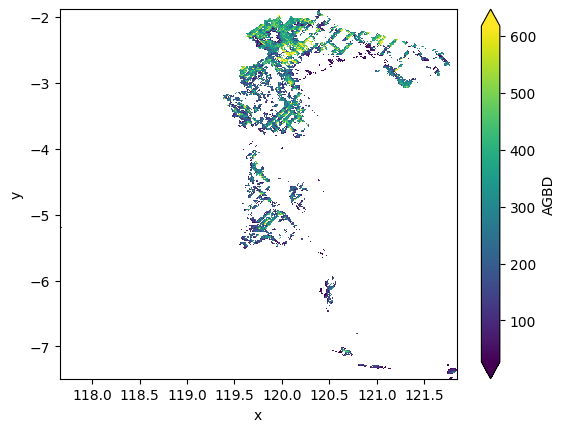

In [6]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr
from dask.diagnostics import ProgressBar

# Menyusun grid spasial yang mencakup seluruh area hutan.
# grid_scale=(0.01, -0.01) = ukuran piksel 0.01 DERAJAT (bukan meter),
# kira-kira 1 km. Negatif di sumbu y = urutan dari utara ke selatan.
grid_params = helpers.fit_geometry(
    geometry=shape(forest_aoi.getInfo()),  # getInfo: tarik geometri dari server GEE ke Python
    grid_crs='EPSG:4326',                  # sistem koordinat lat/lon
    grid_scale=(0.01, -0.01)
)

# Buka citra GEE sebagai Xarray Dataset (masih lazy / belum diunduh)
ds = xr.open_dataset(stack_ds, engine='ee', **grid_params, chunks='auto')

# compute() = benar-benar mengunduh dan memuat data ke RAM
with ProgressBar():
    ds = ds.compute()

# Hapus dimensi waktu karena cuma ada satu periode
ds = ds.squeeze('time').drop_vars('time')

# Cek visual sebaran AGBD (robust=True = abaikan nilai ekstrem untuk skala warna)
ds.AGBD.plot(x='x', y='y', robust=True)

# ===== CELL 7: Xarray -> DataFrame =====

In [7]:
# Setiap piksel jadi satu baris, setiap band jadi satu kolom.
# x dan y (koordinat) jadi index. dropna(how='all') membuang baris
# yang seluruh kolomnya kosong (piksel di luar hutan).
df_dataset = ds.to_dataframe().dropna(how='all')

# Simpan ke CSV sebagai backup agar tidak perlu menarik data GEE lagi
df_dataset.to_csv(os.path.join(ROOT_PATH, 'Satellite_Embedding_Biomass.csv'))

# ===== CELL 8: Train/test split =====

Train: 8518 | Test: 3651


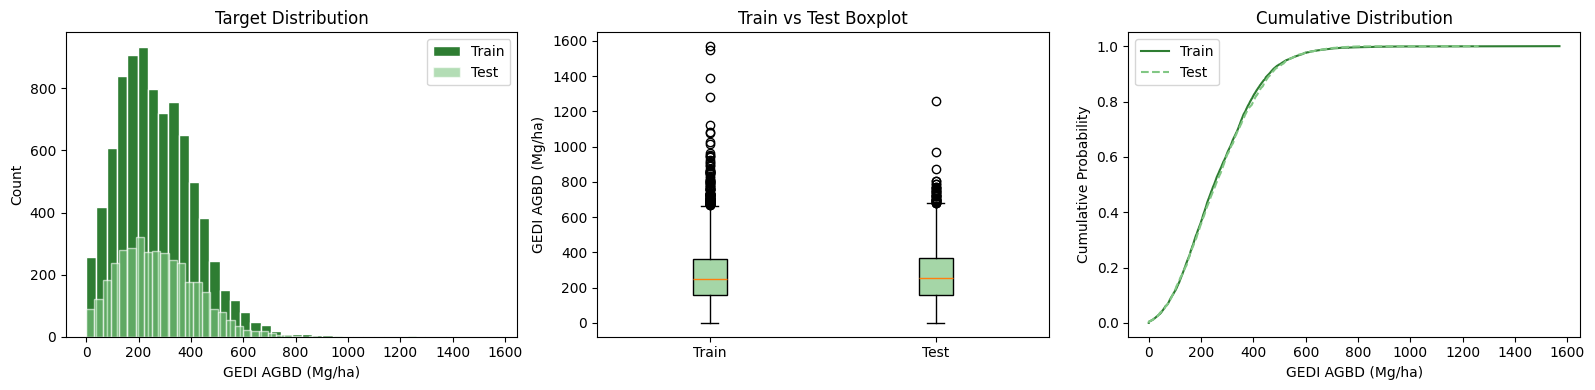

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Buang baris yang masih punya NaN di salah satu kolom (RF sklearn tidak terima NaN)
df_model = df_dataset.dropna()
X = df_model.drop('AGBD', axis=1)   # prediktor = semua kolom selain AGBD
y = df_model['AGBD']                # target = AGBD (Mg/ha)

# Skema pembagian: 70% latih, 30% uji, acak dengan seed 42 (bisa direproduksi)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
print('Train:', len(X_train), '| Test:', len(X_test))

# --- Visualisasi distribusi target (3 panel) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) Histogram: bandingkan sebaran nilai AGBD data latih vs uji
axes[0].hist(y_train, bins=40, color='#2e7d32', edgecolor='white', label='Train')
axes[0].hist(y_test, bins=40, color='#81c784', edgecolor='white', alpha=0.6, label='Test')
axes[0].set_xlabel('GEDI AGBD (Mg/ha)'); axes[0].set_ylabel('Count')
axes[0].set_title('Target Distribution'); axes[0].legend()

# (b) Boxplot: bandingkan median, kuartil, dan outlier
axes[1].boxplot([y_train, y_test], tick_labels=['Train', 'Test'], patch_artist=True,
                boxprops=dict(facecolor='#a5d6a7'))
axes[1].set_ylabel('GEDI AGBD (Mg/ha)'); axes[1].set_title('Train vs Test Boxplot')

# (c) CDF: proporsi kumulatif sampel sampai nilai AGBD tertentu
for d, c, ls, lb in [(y_train, '#2e7d32', '-', 'Train'), (y_test, '#81c784', '--', 'Test')]:
    s = np.sort(d)
    axes[2].plot(s, np.arange(1, len(s) + 1) / len(s), color=c, linestyle=ls, label=lb)
axes[2].set_xlabel('GEDI AGBD (Mg/ha)'); axes[2].set_ylabel('Cumulative Probability')
axes[2].set_title('Cumulative Distribution'); axes[2].legend()

fig.tight_layout()
fig.savefig(os.path.join(ROOT_PATH, '02_sebaran_agbd.png'), dpi=150, bbox_inches='tight')
plt.show()

# ===== CELL 9: Hyperparameter tuning =====

In [9]:
import time
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

def tuning_model(regressor, X_train, y_train):
    """Grid search manual: coba semua kombinasi max_features x n_estimators,
    nilai dengan 5-fold cross-validation (metrik R2), lalu pilih yang terbaik."""
    best_score, best_params = -np.inf, {}

    for p in [1, 2, 3, 4, 5]:               # jumlah fitur yang dipertimbangkan tiap split
        for n in [100, 200, 300, 400, 500]: # jumlah pohon
            t0 = time.time()
            regressor.set_params(max_features=p, n_estimators=n)

            # cv=5: data latih dibagi 5 bagian, bergantian jadi validasi.
            # n_jobs=-1: pakai semua core CPU biar cepat.
            score = cross_val_score(regressor, X_train, y_train,
                                    scoring='r2', cv=5, n_jobs=-1).mean()

            # Simpan kombinasi kalau skornya lebih tinggi dari sebelumnya
            if score > best_score:
                best_score, best_params = score, {'max_features': p, 'n_estimators': n}

            print(f'max_features={p}, n_estimators={n}, R2={score:.4f}, '
                  f'time={(time.time()-t0)/60:.2f} min')

    print('Best Parameters:', best_params)
    print('Best CV R2:', best_score)
    return best_params, best_score

# oob_score=True: hitung skor out-of-bag (evaluasi tambahan dari sampel
# yang tidak terpilih saat bootstrap tiap pohon)
rf = RandomForestRegressor(oob_score=True, random_state=42)
best_params, best_score = tuning_model(rf, X_train, y_train)

max_features=1, n_estimators=100, R2=0.5607, time=0.19 min
max_features=1, n_estimators=200, R2=0.5643, time=0.22 min
max_features=1, n_estimators=300, R2=0.5652, time=0.34 min
max_features=1, n_estimators=400, R2=0.5660, time=0.46 min
max_features=1, n_estimators=500, R2=0.5662, time=0.55 min
max_features=2, n_estimators=100, R2=0.5696, time=0.14 min
max_features=2, n_estimators=200, R2=0.5710, time=0.33 min
max_features=2, n_estimators=300, R2=0.5728, time=0.47 min
max_features=2, n_estimators=400, R2=0.5736, time=0.66 min
max_features=2, n_estimators=500, R2=0.5739, time=0.82 min
max_features=3, n_estimators=100, R2=0.5709, time=0.22 min
max_features=3, n_estimators=200, R2=0.5734, time=0.41 min
max_features=3, n_estimators=300, R2=0.5741, time=0.61 min
max_features=3, n_estimators=400, R2=0.5747, time=0.82 min
max_features=3, n_estimators=500, R2=0.5754, time=1.17 min
max_features=4, n_estimators=100, R2=0.5739, time=0.25 min
max_features=4, n_estimators=200, R2=0.5756, time=0.51 m

# ===== CELL 10: Final model + evaluasi =====

In [10]:
from sklearn.metrics import r2_score, root_mean_squared_error
from scipy.stats import pearsonr

# Latih ulang model memakai parameter terbaik hasil tuning
regr_rf = RandomForestRegressor(
    max_features=best_params['max_features'],
    n_estimators=best_params['n_estimators'],
    oob_score=True, random_state=42)
regr_rf.fit(X_train, y_train)

# Prediksi pada data latih dan data uji
y_train_pred = regr_rf.predict(X_train)
y_test_pred = regr_rf.predict(X_test)

# R2   = proporsi variasi target yang dijelaskan model (makin dekat 1 makin baik)
# RMSE = rata-rata besar kesalahan, satuannya sama dengan target (Mg/ha)
# r    = korelasi Pearson antara nilai observasi dan prediksi
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
rmse_train = root_mean_squared_error(y_train, y_train_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)
r_test, _ = pearsonr(y_test, y_test_pred)

# Bandingkan latih vs uji untuk cek overfitting
# (R2 latih jauh lebih tinggi dari uji = indikasi overfitting)
print(f'Train R2 = {r2_train:.3f} | RMSE = {rmse_train:.2f}')
print(f'Test  R2 = {r2_test:.3f} | RMSE = {rmse_test:.2f} | r = {r_test:.3f}')
print(f'OOB score = {regr_rf.oob_score_:.3f}')

# Tabel feature importance: band embedding mana yang paling berpengaruh
rf_importance = (pd.DataFrame({'Predictor': X_train.columns,
                               'Importance': regr_rf.feature_importances_})
                 .sort_values('Importance', ascending=False).reset_index(drop=True))
print(rf_importance.head(10))

Train R2 = 0.943 | RMSE = 35.82
Test  R2 = 0.618 | RMSE = 92.07 | r = 0.789
OOB score = 0.579
  Predictor  Importance
0       A06    0.053624
1       A24    0.042894
2       A36    0.038097
3       A43    0.032858
4       A03    0.032383
5       A47    0.031637
6       A12    0.029351
7       A25    0.028718
8       A05    0.027444
9       A52    0.026295


# ===== CELL 11: Scatter obs vs pred =====

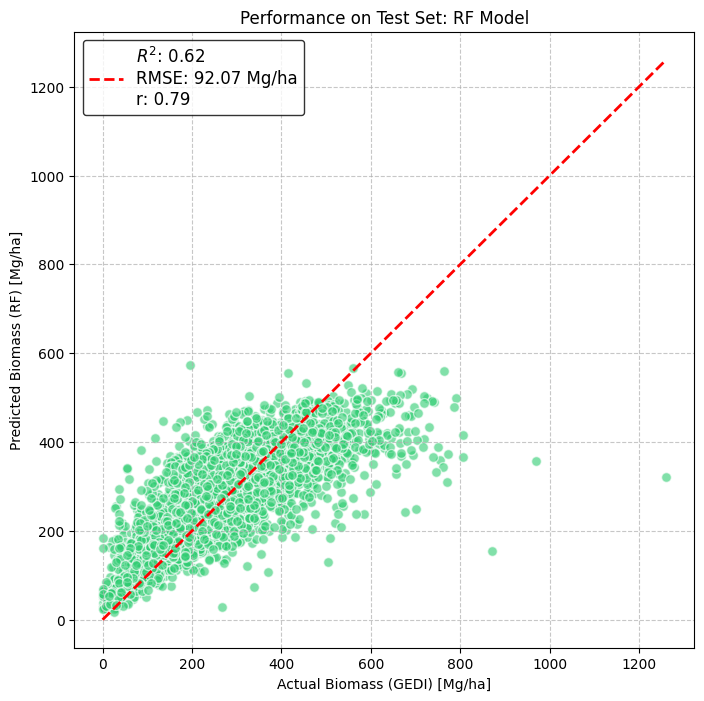

In [11]:
# Teks metrik yang akan muncul di legenda grafik
stats_label = f'$R^2$: {r2_test:.2f}\nRMSE: {rmse_test:.2f} Mg/ha\nr: {r_test:.2f}'

plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_test_pred, alpha=0.6, color='#2ecc71', edgecolor='white', s=50)

# Garis 1:1 (kondisi ideal: prediksi = observasi). Makin dekat titik ke garis, makin akurat.
lo = min(y_test.min(), y_test_pred.min())
hi = max(y_test.max(), y_test_pred.max())
plt.plot([lo, hi], [lo, hi], 'r--', lw=2, label=stats_label)

plt.legend(loc='upper left', fontsize=12, frameon=True, edgecolor='black')
plt.xlabel('Actual Biomass (GEDI) [Mg/ha]')
plt.ylabel('Predicted Biomass (RF) [Mg/ha]')
plt.title('Performance on Test Set: RF Model')
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig(os.path.join(ROOT_PATH, '03_scatter_obs_vs_pred.png'), dpi=300, bbox_inches='tight')
plt.show()

# ===== CELL 12: Feature importance =====

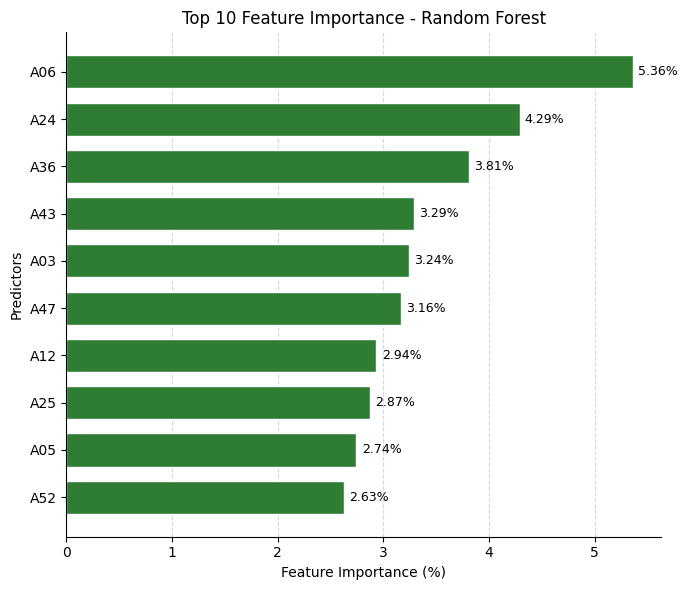

In [12]:
# ascending=True supaya batang tertinggi tampil paling atas di grafik horizontal
top10 = rf_importance.head(10).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(7, 6))
bars = ax.barh(top10['Predictor'], top10['Importance'] * 100,   # x100 jadi persen
               color='#2e7d32', edgecolor='white', height=0.7)

# Tulis nilai persen di ujung tiap batang
for b in bars:
    w = b.get_width()
    ax.text(w + 0.05, b.get_y() + b.get_height() / 2, f'{w:.2f}%', va='center', fontsize=9)

ax.set_xlabel('Feature Importance (%)'); ax.set_ylabel('Predictors')
ax.set_title('Top 10 Feature Importance - Random Forest')
ax.grid(axis='x', linestyle='--', alpha=0.5); ax.set_axisbelow(True)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)  # rapikan bingkai
plt.tight_layout()
plt.savefig(os.path.join(ROOT_PATH, '04_feature_importance.png'), dpi=300, bbox_inches='tight')
plt.show()

# ===== CELL 13: Spatial inference =====

Min: 7.59 Mg/ha
Max: 1144.88 Mg/ha


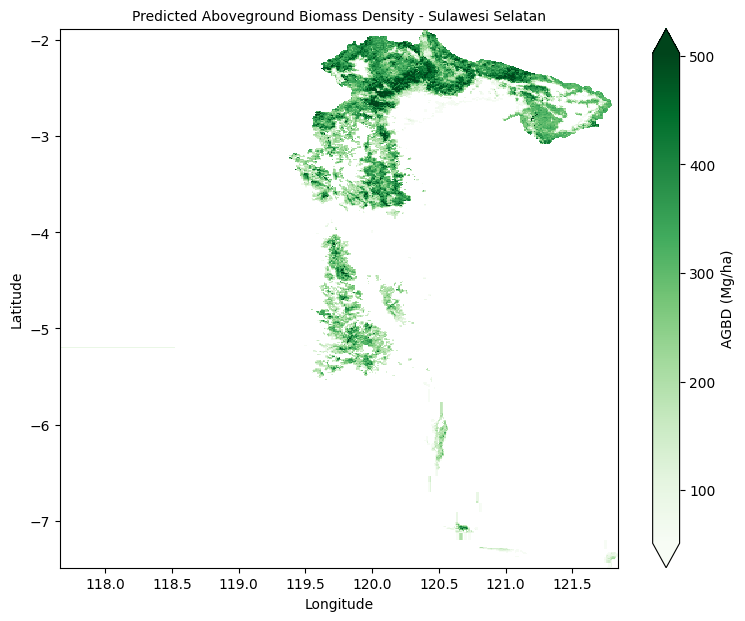

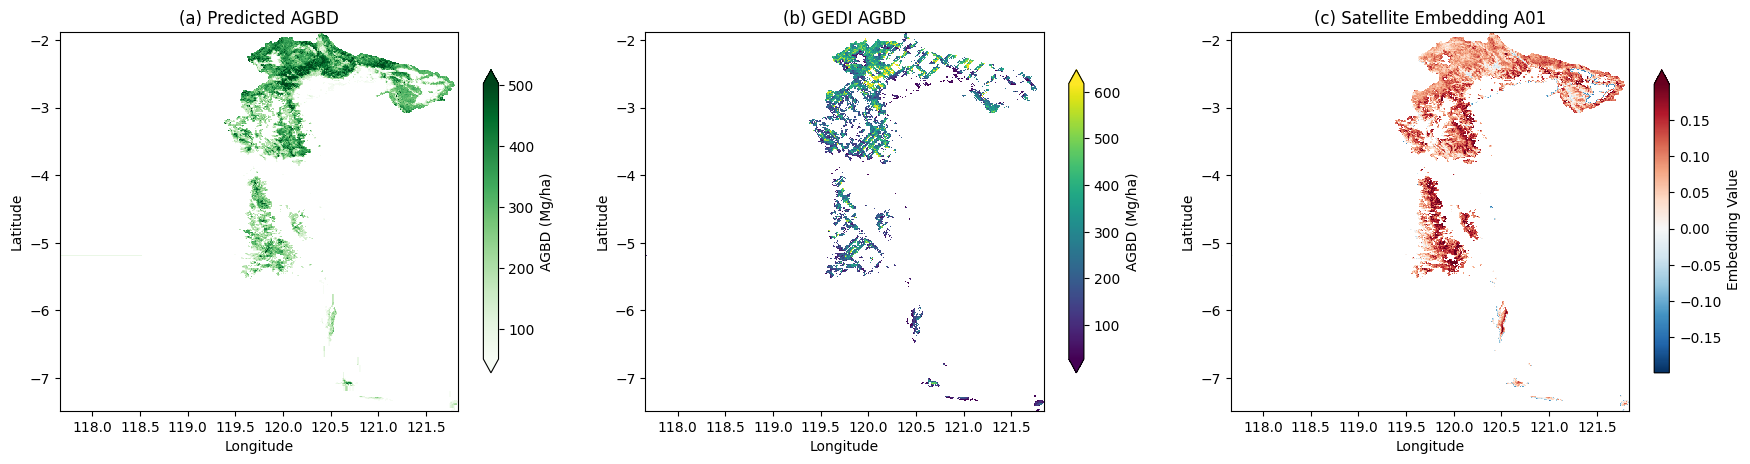

In [13]:
# Buang kolom target, lalu dropna() supaya hanya baris dengan semua prediktor valid.
df_inference = df_dataset.drop(columns=['AGBD']).dropna()

# Urutan kolom harus SAMA dengan saat training (X_train.columns),
# kalau tidak, model bisa salah baca fitur.
df_inference['abgd_predic'] = regr_rf.predict(df_inference[X_train.columns])

# Cek rentang nilai prediksi (masuk akal tidak, misal tidak negatif/ekstrem)
print(f"Min: {df_inference['abgd_predic'].min():.2f} Mg/ha")
print(f"Max: {df_inference['abgd_predic'].max():.2f} Mg/ha")

# Kembalikan ke bentuk Xarray (grid x,y) agar bisa diplot sebagai peta dan diekspor jadi raster
data_inference = df_inference.to_xarray().sortby('x').sortby('y')

# Peta prediksi AGBD
plt.figure(figsize=(9, 7))
data_inference.abgd_predic.plot(x='x', y='y', cmap='Greens', robust=True,
                                cbar_kwargs={'label': 'AGBD (Mg/ha)'})
plt.title(f'Predicted Aboveground Biomass Density - {PROVINSI}', fontsize=10)
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.savefig(os.path.join(ROOT_PATH, '05_peta_prediksi_agbd.png'), dpi=300, bbox_inches='tight')
plt.show()

# Perbandingan 3 panel: prediksi vs GEDI (referensi) vs salah satu band embedding
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

data_inference.abgd_predic.plot(ax=ax[0], x='x', y='y', cmap='Greens', robust=True,
                                cbar_kwargs={'label': 'AGBD (Mg/ha)', 'shrink': 0.8})
ax[0].set_title('(a) Predicted AGBD')

ds.AGBD.plot(ax=ax[1], x='x', y='y', robust=True,
             cbar_kwargs={'label': 'AGBD (Mg/ha)', 'shrink': 0.8})
ax[1].set_title('(b) GEDI AGBD')

ds.A01.plot(ax=ax[2], x='x', y='y', robust=True,
            cbar_kwargs={'label': 'Embedding Value', 'shrink': 0.8})
ax[2].set_title('(c) Satellite Embedding A01')

for a in ax:                       # label sumbu sama untuk ketiga panel
    a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
plt.tight_layout(pad=2)
plt.savefig(os.path.join(ROOT_PATH, 'Biomass_Embedding_GEDI.png'), dpi=300, bbox_inches='tight')
plt.show()


# ===== CELL 14: Simpan model & GeoTIFF =====

In [ ]:
import joblib
import rioxarray

# Simpan model ke file .pkl supaya tidak perlu training ulang
MODEL_PATH = os.path.join(ROOT_PATH, 'Best_RF_Model.pkl')
joblib.dump(regr_rf, MODEL_PATH)

# Tes muat ulang model untuk memastikan file tersimpan dengan benar
agb_model = joblib.load(MODEL_PATH)
print('Model loaded:', agb_model.get_params())

# Tambahkan info CRS (EPSG:4326) ke raster prediksi.
# Catatan: write_crs hanya menulis label CRS, tidak mengubah koordinat.
save_data = data_inference['abgd_predic'].rio.write_crs('EPSG:4326')

# Ekspor jadi GeoTIFF agar bisa dibuka di QGIS / ArcGIS
output_path = os.path.join(ROOT_PATH, 'abgd_predic.tif')
save_data.rio.to_raster(output_path)
print('GeoTIFF saved:', output_path)